In [ ]:
import kagglehub

path = kagglehub.dataset_download("sharmajicoder/amazon-e-commerce")
print(path)

100%|██████████| 38.2M/38.2M [00:00<00:00, 66.0MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/sharmajicoder/amazon-e-commerce/versions/1


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

In [ ]:
import os

csv_files = []
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

df = pd.read_csv(csv_files[0])
df.head()

,user_id,product_id,category,subcategory,brand,price,discount,final_price,rating,review_count,stock,seller_id,seller_rating,purchase_date,shipping_time_days,location,device,payment_method,is_returned,delivery_status
0,U356787,P39256,Electronics,Mobile,H&M,33090.51,10.46,29629.31,4.9,43,71,S2679,4.3,2025-03-04,6,Bangalore,Tablet,UPI,True,Returned
1,U198246,P38657,Sports,Outdoor,Samsung,9368.97,5.32,8870.73,3.9,13,119,S9279,4.9,2025-12-12,1,Delhi,Tablet,UPI,True,Returned
2,U539898,P38893,Sports,Fitness,H&M,14756.85,26.00,10919.43,4.2,46,229,S5557,4.9,2024-04-25,1,Chennai,Mobile App,Credit Card,True,Returned
3,U325772,P54118,Beauty,Makeup,Sony,668.83,24.81,502.91,3.8,6,52,S2519,3.1,2025-12-18,2,Mumbai,Web,UPI,False,In Transit
4,U865179,P70217,Home,Decor,Sony,10881.29,48.63,5589.58,4.0,48,274,S3045,2.6,2024-05-16,5,Delhi,Web,UPI,False,Delayed


In [ ]:
# Inspect
df.info()

# Missing values
df.isnull().sum()

# Remove duplicates
df.drop_duplicates(inplace=True)

# Fix datatypes
df["purchase_date"] = pd.to_datetime(df["purchase_date"])

# Feature engineering
df["month"] = df["purchase_date"].dt.month_name()
df["year"] = df["purchase_date"].dt.year


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 20 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   user_id             1000000 non-null  object 
 1   product_id          1000000 non-null  object 
 2   category            1000000 non-null  object 
 3   subcategory         1000000 non-null  object 
 4   brand               1000000 non-null  object 
 5   price               1000000 non-null  float64
 6   discount            1000000 non-null  float64
 7   final_price         1000000 non-null  float64
 8   rating              1000000 non-null  float64
 9   review_count        1000000 non-null  int64  
 10  stock               1000000 non-null  int64  
 11  seller_id           1000000 non-null  object 
 12  seller_rating       1000000 non-null  float64
 13  purchase_date       1000000 non-null  object 
 14  shipping_time_days  1000000 non-null  int64  
 15  location        

In [ ]:
total_revenue = df["final_price"].sum()
print("Total Revenue:", total_revenue)

total_orders = df.shape[0]
print("Total Orders:", total_orders)

total_customers = df["user_id"].nunique()
print("Total Customers:", total_customers)

total_products = df["product_id"].nunique()
print("Total Products:", total_products)

aov = df["final_price"].sum() / df.shape[0]
print("Average Order Value:", aov)

return_rate = df["is_returned"].mean() * 100
print("Return Rate %:", return_rate)

avg_discount = df["discount"].mean()
print("Average Discount:", avg_discount)

avg_rating = df["rating"].mean()
print("Average Rating:", avg_rating)

Total Revenue: 9938876984.9
Total Orders: 1000000
Total Customers: 603815
Total Products: 89999
Average Order Value: 9938.8769849
Return Rate %: 11.599
Average Discount: 28.996160609999986
Average Rating: 3.9272262


In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12,6)

os.makedirs("images", exist_ok=True)

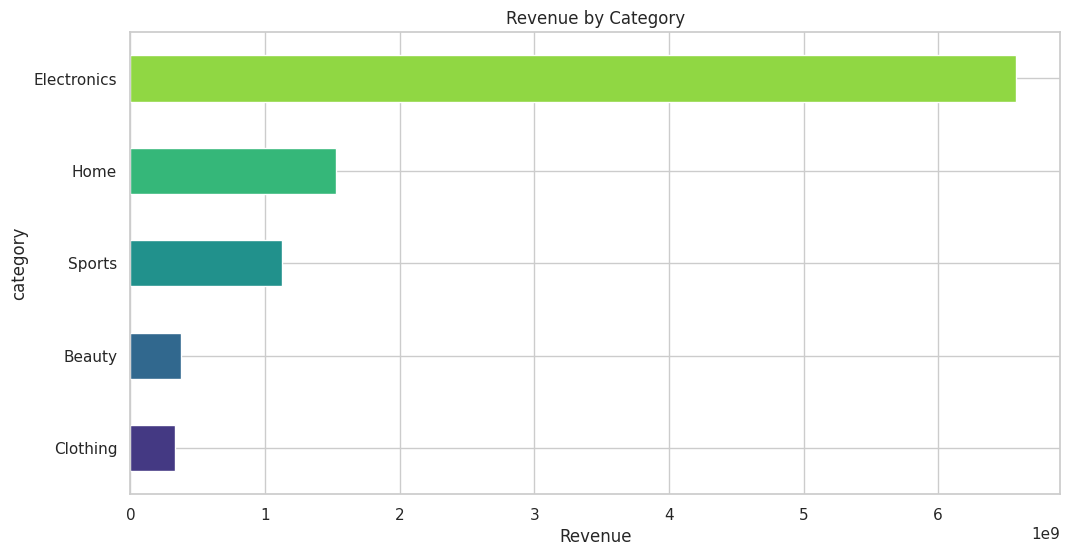

In [ ]:
data = df.groupby("category")["final_price"].sum().sort_values()

plt.figure()
data.plot(kind="barh", color=sns.color_palette("viridis", len(data)))

plt.title("Revenue by Category")
plt.xlabel("Revenue")

plt.savefig("images/revenue_by_category.png", bbox_inches="tight")
plt.show()

/tmp/ipykernel_1196/2697650394.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=data.values, y=data.index, palette="rocket")


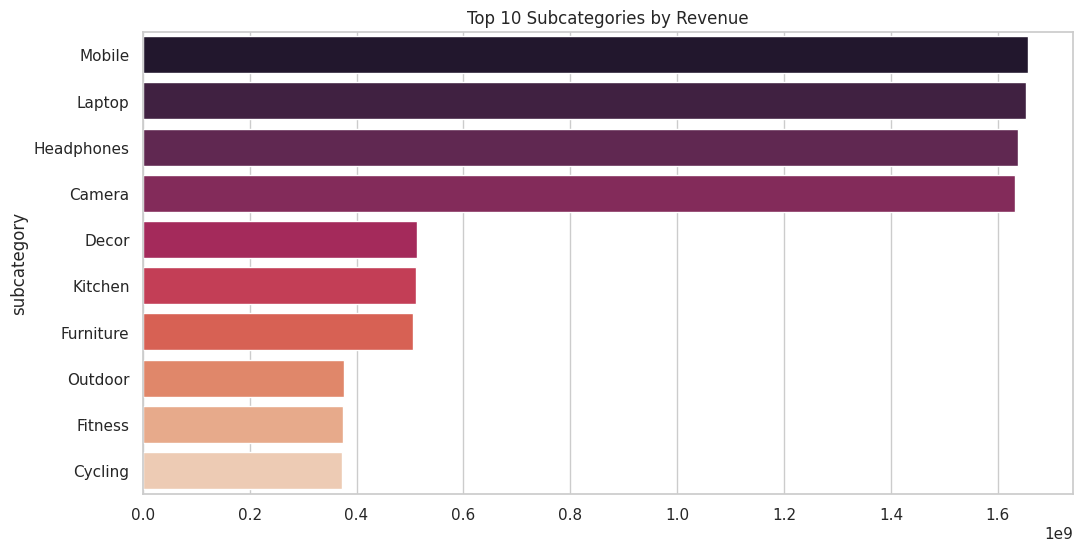

In [ ]:
data = df.groupby("subcategory")["final_price"].sum().sort_values(ascending=False).head(10)

plt.figure()
sns.barplot(x=data.values, y=data.index, palette="rocket")

plt.title("Top 10 Subcategories by Revenue")

plt.savefig("images/top_subcategories.png", bbox_inches="tight")
plt.show()

/tmp/ipykernel_1196/14792719.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=data.values, y=data.index, palette="mako")


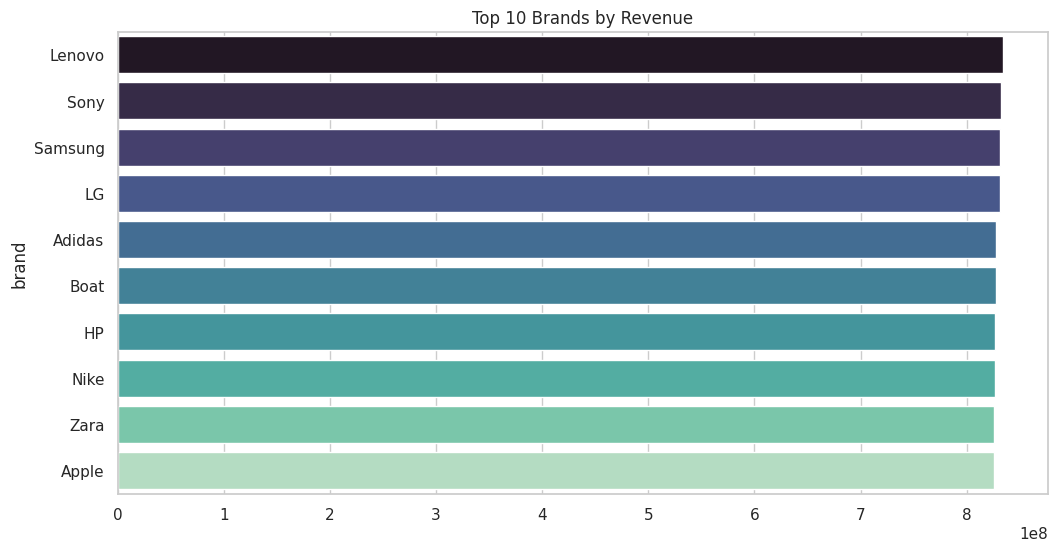

In [ ]:
data = df.groupby("brand")["final_price"].sum().sort_values(ascending=False).head(10)

plt.figure()
sns.barplot(x=data.values, y=data.index, palette="mako")

plt.title("Top 10 Brands by Revenue")

plt.savefig("images/top_brands.png", bbox_inches="tight")
plt.show()

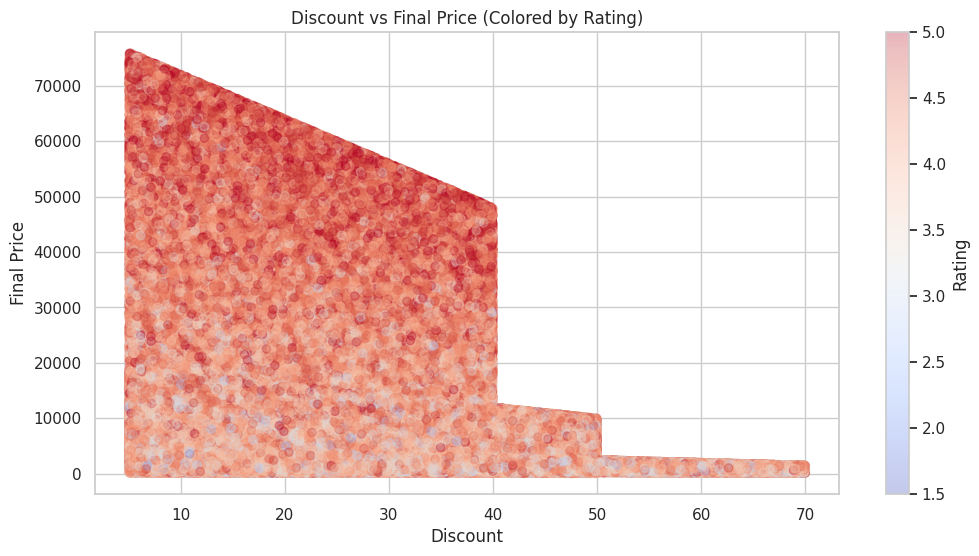

In [ ]:
plt.scatter(df["discount"], df["final_price"], alpha=0.3, c=df["rating"], cmap="coolwarm")

plt.title("Discount vs Final Price (Colored by Rating)")
plt.xlabel("Discount")
plt.ylabel("Final Price")

plt.colorbar(label="Rating")

plt.savefig("images/price_vs_final_price.png", bbox_inches="tight")
plt.show()

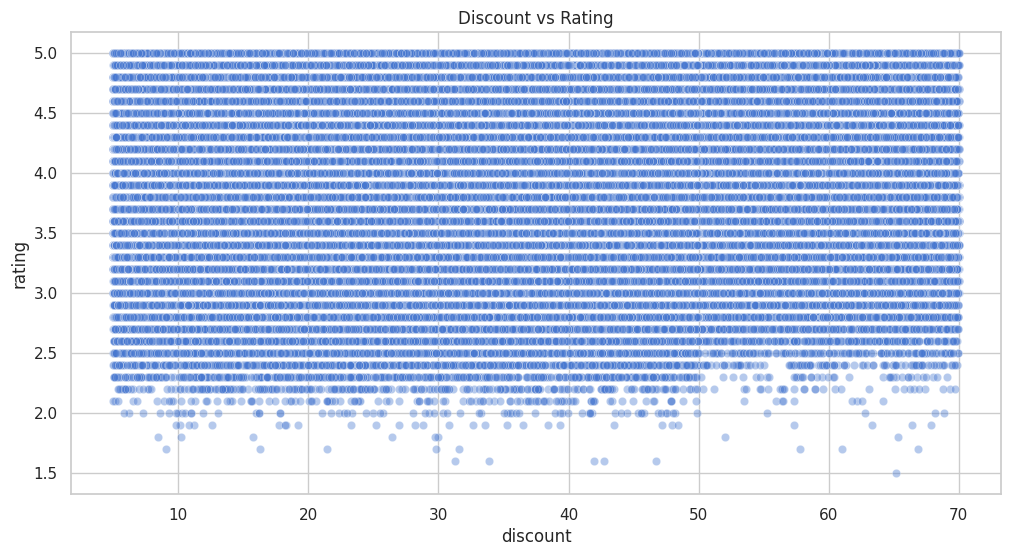

In [ ]:
plt.figure()

sns.scatterplot(data=df, x="discount", y="rating", alpha=0.4)

plt.title("Discount vs Rating")

plt.savefig("images/discount_vs_rating.png", bbox_inches="tight")
plt.show()

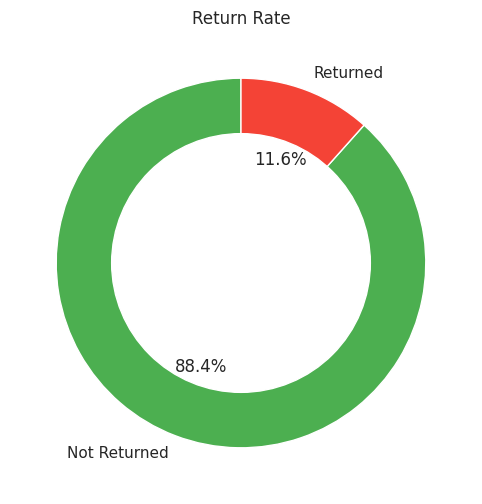

In [ ]:
returns = df["is_returned"].value_counts()

plt.figure()

plt.pie(
    returns,
    labels=["Not Returned", "Returned"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4CAF50", "#F44336"]
)

centre = plt.Circle((0,0),0.70,fc="white")
plt.gca().add_artist(centre)

plt.title("Return Rate")

plt.savefig("images/return_rate.png", bbox_inches="tight")
plt.show()

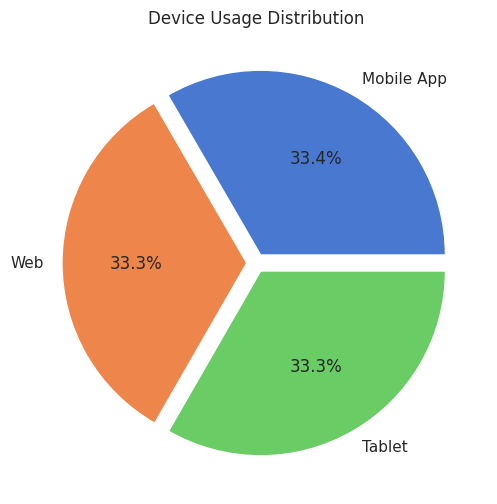

In [ ]:
data = df["device"].value_counts()

plt.figure()
plt.pie(data, labels=data.index, autopct="%1.1f%%", explode=[0.05]*len(data))

plt.title("Device Usage Distribution")

plt.savefig("images/device_usage.png", bbox_inches="tight")
plt.show()

/tmp/ipykernel_1196/2300777668.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=data.values, y=data.index, palette="viridis")


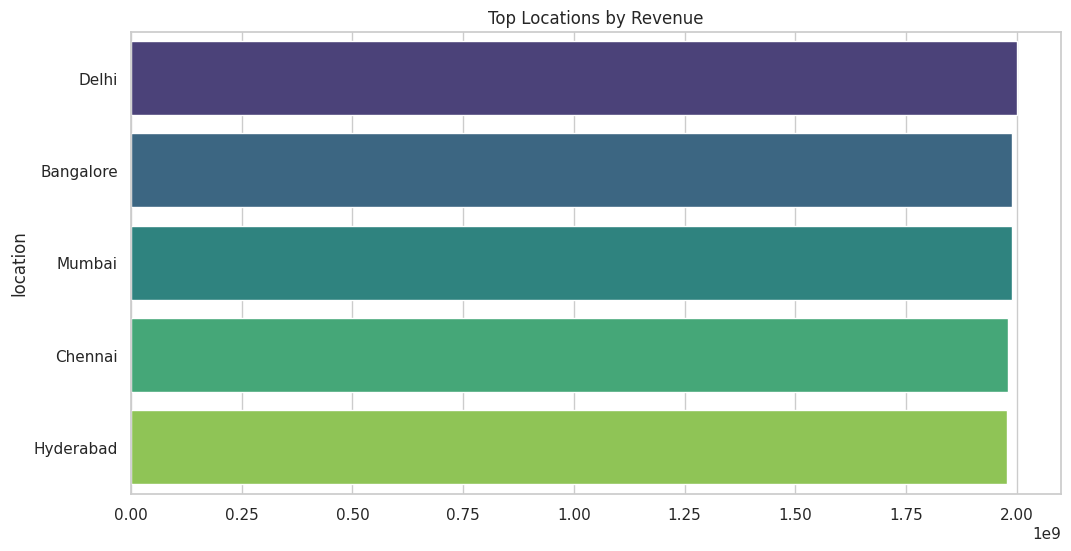

In [ ]:
data = df.groupby("location")["final_price"].sum().sort_values(ascending=False).head(10)

plt.figure()
sns.barplot(x=data.values, y=data.index, palette="viridis")

plt.title("Top Locations by Revenue")

plt.savefig("images/location_revenue.png", bbox_inches="tight")
plt.show()

/tmp/ipykernel_1196/1745779276.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=data.values, y=data.index, palette="cubehelix")


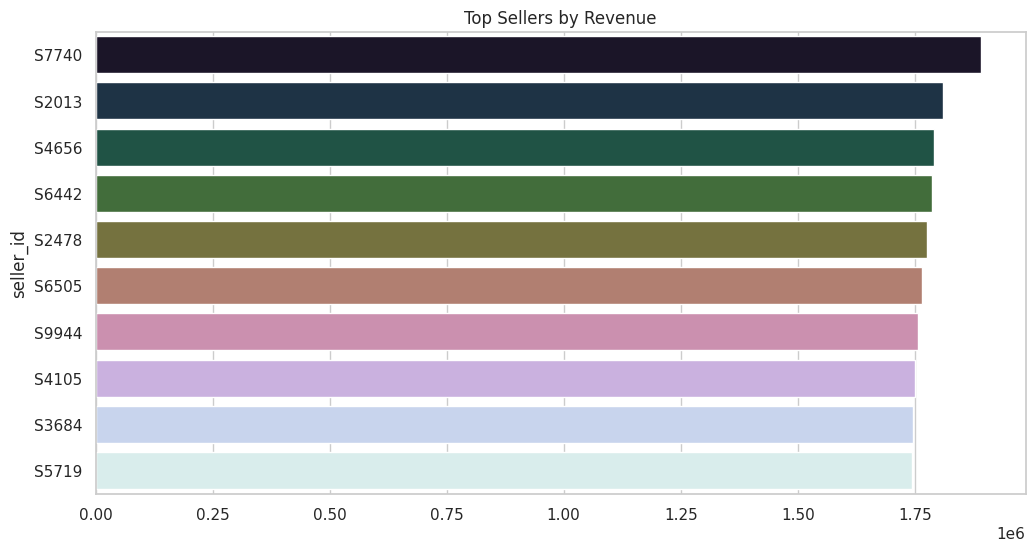

In [ ]:
data = df.groupby("seller_id")["final_price"].sum().sort_values(ascending=False).head(10)

plt.figure()
sns.barplot(x=data.values, y=data.index, palette="cubehelix")

plt.title("Top Sellers by Revenue")

plt.savefig("images/seller_performance.png", bbox_inches="tight")
plt.show()

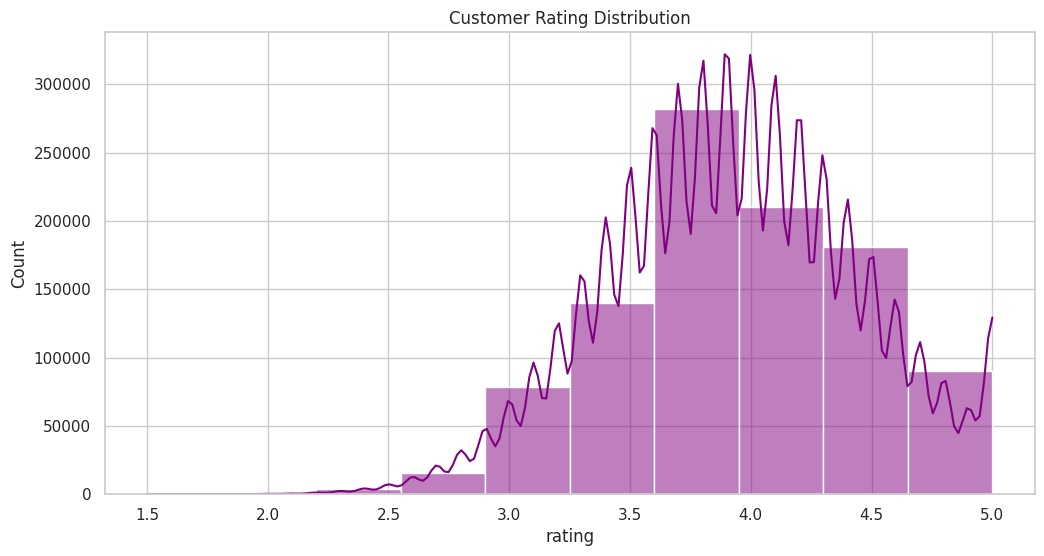

In [ ]:
plt.figure()

sns.histplot(df["rating"], bins=10, kde=True, color="purple")

plt.title("Customer Rating Distribution")

plt.savefig("images/rating_distribution.png", bbox_inches="tight")
plt.show()

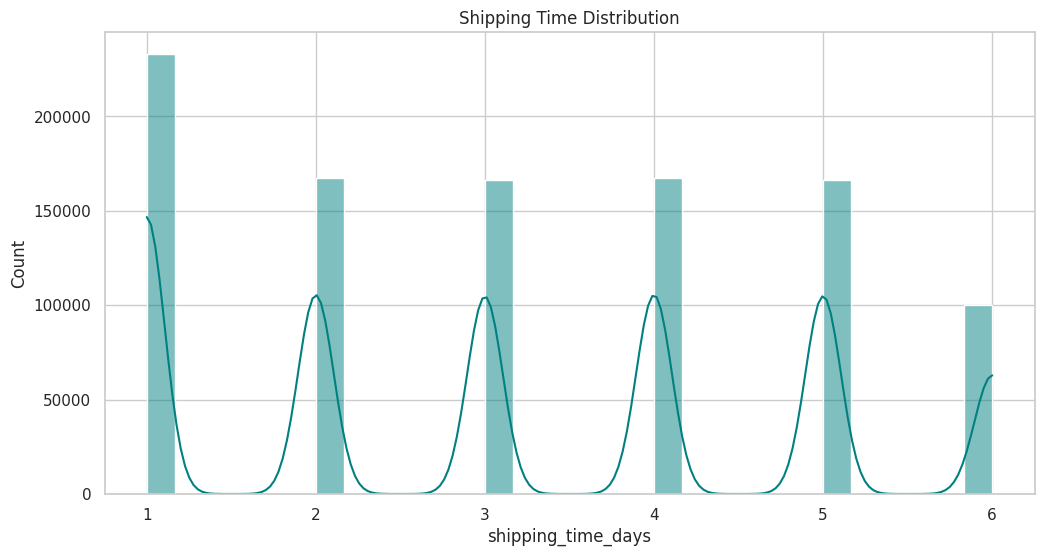

In [ ]:
plt.figure()

sns.histplot(df["shipping_time_days"], bins=30, kde=True, color="teal")

plt.title("Shipping Time Distribution")

plt.savefig("images/shipping_distribution.png", bbox_inches="tight")
plt.show()

/tmp/ipykernel_1196/1549278378.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="category", y="rating", data=df, palette="Set3")


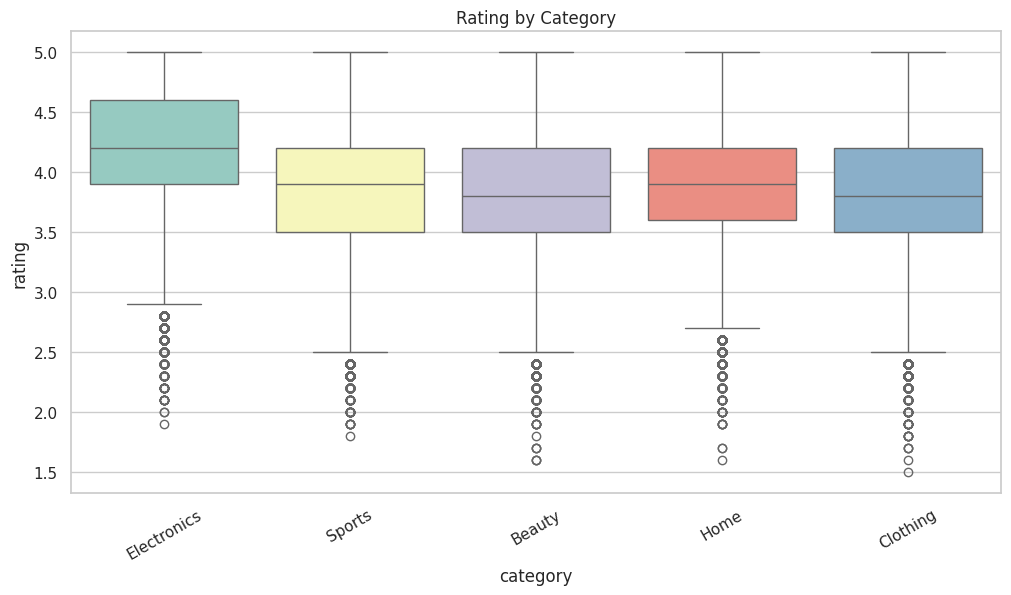

In [ ]:
plt.figure()

sns.boxplot(x="category", y="rating", data=df, palette="Set3")

plt.title("Rating by Category")

plt.xticks(rotation=30)

plt.savefig("images/category_rating.png", bbox_inches="tight")
plt.show()

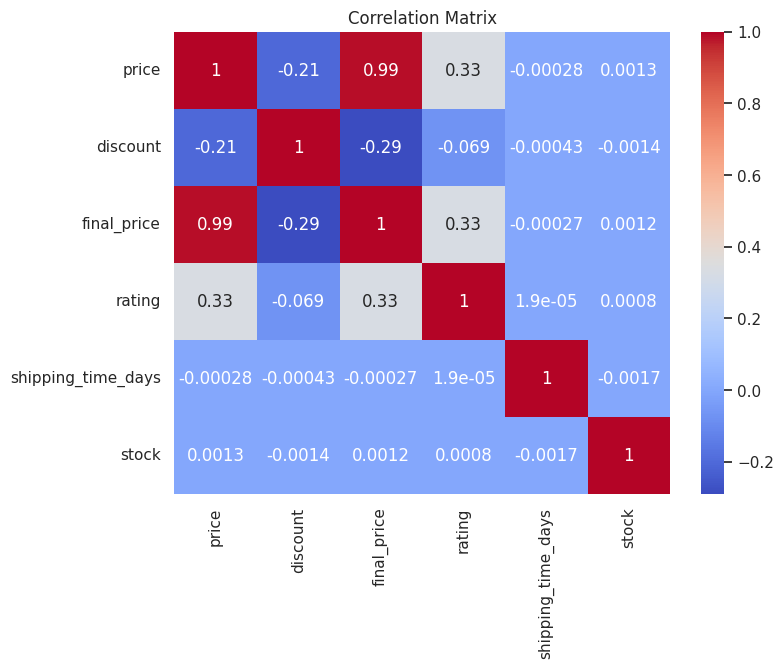

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[["price","discount","final_price","rating","shipping_time_days","stock"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.savefig("images/correlation_matrix.png", bbox_inches="tight")
plt.show()

SQL

In [ ]:
import sqlite3
conn = sqlite3.connect("amazon.db")
d = df.copy()
d["purchase_date"] = d["purchase_date"].dt.strftime("%Y-%m-%d")
d["is_returned"] = d["is_returned"].astype(int)
d.to_sql("orders", conn, if_exists="replace", index=False, chunksize=100000)

def q(sql):
    return pd.read_sql(sql, conn)

q("SELECT COUNT(*) AS n FROM orders")

,n
0,1000000


In [ ]:
# 1. KPI summary

q("""
SELECT COUNT(*) AS orders, COUNT(DISTINCT user_id) AS customers,
       ROUND(SUM(final_price)) AS revenue, ROUND(AVG(final_price)) AS avg_order_value,
       ROUND(100.0*AVG(is_returned),1) AS return_rate_pct
FROM orders;
""")

,orders,customers,revenue,avg_order_value,return_rate_pct
0,1000000,603815,9.938877e+09,9939.0,11.6


In [ ]:
# 2. Revenue share by category

q("""
SELECT category, ROUND(SUM(final_price)) AS revenue,
       ROUND(100.0*SUM(final_price)/SUM(SUM(final_price)) OVER (),1) AS pct_of_total
FROM orders GROUP BY category ORDER BY revenue DESC;
 """)

,category,revenue,pct_of_total
0,Electronics,6.579048e+09,66.2
1,Home,1.529978e+09,15.4
2,Sports,1.124849e+09,11.3
3,Beauty,3.759517e+08,3.8
4,Clothing,3.290504e+08,3.3


In [ ]:
# 3. Month-over-month revenue growth

q("""
WITH monthly AS (
  SELECT strftime('%Y-%m', purchase_date) AS ym, SUM(final_price) AS revenue
  FROM orders GROUP BY ym)
SELECT ym, ROUND(revenue) AS revenue,
       ROUND(100.0*(revenue-LAG(revenue) OVER (ORDER BY ym))/LAG(revenue) OVER (ORDER BY ym),1) AS mom_growth_pct
FROM monthly ORDER BY ym;
 """)

,ym,revenue,mom_growth_pct
0,2024-03,13888018.0,NaN
1,2024-04,409629213.0,2849.5
2,2024-05,420785553.0,2.7
3,2024-06,405171530.0,-3.7
4,2024-07,421788247.0,4.1
5,2024-08,420222014.0,-0.4
6,2024-09,403999735.0,-3.9
7,2024-10,423567224.0,4.8
8,2024-11,411893575.0,-2.8
9,2024-12,422066333.0,2.5


In [ ]:
# 4. Return rate by category and payment method

q("""
SELECT category, payment_method, COUNT(*) AS orders,
       ROUND(100.0*AVG(is_returned),1) AS return_rate_pct
FROM orders GROUP BY category, payment_method ORDER BY return_rate_pct DESC;
 """)

,category,payment_method,orders,return_rate_pct
0,Beauty,Cash on Delivery,49977,11.9
1,Sports,Debit Card,49698,11.9
2,Beauty,UPI,49845,11.8
3,Clothing,Cash on Delivery,50276,11.8
4,Clothing,Credit Card,50117,11.8
5,Beauty,Credit Card,49673,11.7
6,Clothing,Debit Card,49636,11.7
7,Clothing,UPI,49795,11.7
8,Home,Credit Card,50166,11.7
9,Beauty,Debit Card,49832,11.6


In [ ]:
# 5. Return rate and rating by discount band

q("""
SELECT CASE WHEN discount<10 THEN '0-10' WHEN discount<20 THEN '10-20'
            WHEN discount<30 THEN '20-30' WHEN discount<40 THEN '30-40' ELSE '40+' END AS discount_band,
       COUNT(*) AS orders, ROUND(100.0*AVG(is_returned),1) AS return_rate_pct,
       ROUND(AVG(rating),2) AS avg_rating
FROM orders GROUP BY discount_band ORDER BY discount_band;
 """)

,discount_band,orders,return_rate_pct,avg_rating
0,0-10,94712,11.6,3.97
1,10-20,224301,11.7,3.95
2,20-30,224000,11.5,3.95
3,30-40,223825,11.6,3.95
4,40+,233162,11.6,3.85


In [ ]:
# 6. Top 3 sellers per category

q("""
WITH seller_rev AS (
  SELECT category, seller_id, SUM(final_price) AS revenue FROM orders GROUP BY category, seller_id),
ranked AS (
  SELECT category, seller_id, revenue,
         RANK() OVER (PARTITION BY category ORDER BY revenue DESC) AS rnk FROM seller_rev)
SELECT category, seller_id, ROUND(revenue) AS revenue, rnk
FROM ranked WHERE rnk<=3 ORDER BY category, rnk;
 """)

,category,seller_id,revenue,rnk
0,Beauty,S6862,89018.0,1
1,Beauty,S1809,87054.0,2
2,Beauty,S8694,84204.0,3
3,Clothing,S5569,73004.0,1
4,Clothing,S1308,71134.0,2
5,Clothing,S3466,70368.0,3
6,Electronics,S7740,1449990.0,1
7,Electronics,S2478,1440918.0,2
8,Electronics,S3684,1436707.0,3
9,Home,S1760,339531.0,1


In [ ]:
# 7. One time vs repeat customers

q("""
WITH cust AS (
  SELECT user_id, COUNT(*) AS n_orders, SUM(final_price) AS spend FROM orders GROUP BY user_id)
SELECT CASE WHEN n_orders=1 THEN 'One time' ELSE 'Repeat' END AS customer_type,
       COUNT(*) AS customers, ROUND(SUM(spend)) AS revenue,
       ROUND(100.0*SUM(spend)/(SELECT SUM(final_price) FROM orders),1) AS pct_of_revenue
FROM cust GROUP BY customer_type;

 """)

,customer_type,customers,revenue,pct_of_revenue
0,One time,329745,3.266922e+09,32.9
1,Repeat,274070,6.671955e+09,67.1


In [ ]:
# 8. Orders priced above their category average

q("""
WITH cat_avg AS (SELECT category, AVG(final_price) AS avg_price FROM orders GROUP BY category)
SELECT o.category, COUNT(*) AS orders_above_avg,
       ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM orders o2 WHERE o2.category=o.category),1) AS pct_of_category_orders
FROM orders o JOIN cat_avg c ON o.category=c.category
WHERE o.final_price>c.avg_price GROUP BY o.category ORDER BY orders_above_avg DESC;
 """)

,category,orders_above_avg,pct_of_category_orders
0,Electronics,98158,49.1
1,Home,96662,48.1
2,Sports,96431,48.2
3,Beauty,96025,48.2
4,Clothing,88325,44.2


In [ ]:
# 9. Does shipping time affect ratings

q("""
SELECT shipping_time_days, COUNT(*) AS orders, ROUND(AVG(rating),3) AS avg_rating
FROM orders GROUP BY shipping_time_days ORDER BY shipping_time_days;
 """)

,shipping_time_days,orders,avg_rating
0,1,232944,3.927
1,2,167372,3.927
2,3,166095,3.928
3,4,167347,3.927
4,5,166424,3.928
5,6,99818,3.927


In [ ]:
Q10 = """
SELECT strftime('%Y-%m-01', purchase_date) AS month_start, category, device, location,
       payment_method, COUNT(*) AS orders, ROUND(SUM(final_price),2) AS revenue,
       SUM(is_returned) AS returned_orders, ROUND(SUM(rating),1) AS rating_sum
FROM orders GROUP BY 1,2,3,4,5
"""
q(Q10).to_csv("dashboard_data.csv", index=False)
from google.colab import files
files.download("dashboard_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>